In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Part 9: Properties of MLEs {-}

\lhead{Part 9: Properties of MLEs}

\lfoot{Financial Data Science}

\rfoot{\footnotesize Page \thepage\ of \pageref{LastPage}}

\cfoot{Updated \today}

## Approximate Normality of MLE {-}

Maximum likelihood estimators are popular because of their desirable statistical properties. A primary result is that, under general conditions, the MLE is approximately normally distributed with variance that can be calculated without much difficulty.

To start, we review a concept from calculus:

**Exercise:** Consider a univariate function $f(t)$ that is minimized at $\hat t$. Describe the properties of
\begin{equation*}
   \frac{d^2 \!f}{d t^2} \Large|_{t = \hat t}
\end{equation*}

\answerlines{10}

\newpage

The previous result is the basis for a remarkably simple connection between (1) the second deriviative of the negative log-likelihood at its minimum and (2) the variance of the MLE.

**Normality of MLE (Single Parameter Case):** Assume that $\hat \theta$ is the MLE for a real-valued parameter. Under *regularity conditions*, $\hat \theta$ is approximately normal with mean equal to its true value and variance equal to
\begin{equation*}
   \left(-\frac{d^2 \ell(\theta)}{d \theta^2} \Large|_{\theta = \hat \theta}\right)^{-1}
\end{equation*}

The intuition behind this result is the following: When the negative log-likelihood has a "sharp" minimum (large second derivative at the minimum), there is greater certainty in the location of the true parameter value (smaller variance for $\hat \theta$).

The approximate normality of the MLE is a direct result of the central limit theorem. This result will lead to a simple way to construct confidence intervals and hypothesis tests.

\newpage

**Example:** Suppose that $X_1, X_2, \ldots, X_n$ are iid Exponential$(\lambda)$.

The figure below shows three negative log-likelihood functions, based on three samples simulated using $n=100$, $n=250$, and $n=400$.

Note how broad the minimum is in the case $n=100$, reflecting the greater uncertainty in the estimator.

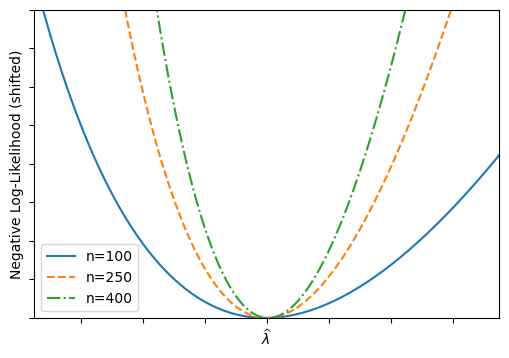

In [2]:
from scipy.stats import expon

np.random.seed(0)
lamgrid = np.arange(0.1,3.0,0.01)

plt.figure(figsize=[6,4])

x = expon.rvs(scale=1/1.3,size=100)
neg_ell_lambda = [-np.sum(expon.logpdf(x,scale=1/lam)) for lam in lamgrid]
plt.plot(lamgrid-lamgrid[np.argmin(neg_ell_lambda)],
         neg_ell_lambda-min(neg_ell_lambda),label="n=100")

x = expon.rvs(scale=1/1.3,size=250)
neg_ell_lambda = [-np.sum(expon.logpdf(x,scale=1/lam)) for lam in lamgrid]
plt.plot(lamgrid-lamgrid[np.argmin(neg_ell_lambda)],
         neg_ell_lambda-min(neg_ell_lambda),label="n=250",linestyle="--")

x = expon.rvs(scale=1/1.3,size=400)
neg_ell_lambda = [-np.sum(expon.logpdf(x,scale=1/lam)) for lam in lamgrid]
plt.plot(lamgrid-lamgrid[np.argmin(neg_ell_lambda)],
         neg_ell_lambda-min(neg_ell_lambda),label="n=400",linestyle="-.")

plt.xlim([-0.75,0.75])
plt.ylim([0,20])
plt.tick_params(labelbottom=False, labelleft=False)
plt.xlabel("$\widehat \lambda$")
plt.ylabel("Negative Log-Likelihood (shifted)")

plt.legend()
plt.show()

We had previously derived the negative log-likelihood in this case to be
\begin{equation*}
 -\ell(\lambda) = -n \log(\lambda) + \lambda \sum_{i=1}^n x_i,
\end{equation*}
so we can find its second derivative as
\begin{equation*}
 -\frac{d^2\ell(\lambda)}{d \lambda^2} = n/\lambda^2
\end{equation*}
and the variance of the MLE is approximately
\begin{equation*}
 \left(-\frac{d^2\ell(\lambda)}{d \lambda^2}\Large|_{\lambda = \hat \lambda}\right)^{\!-1} = \hat \lambda^2/n.
\end{equation*}

\newpage

**What are "regularity conditions?"**

In their classic text, *Statistical Inference*, Casella and Berger write that

> ... "under suitable regularity conditions" is a somewhat abused phrase, as with enough assumptions we can probably prove whatever we want. However, "regularlity conditions" are typically very technical, rather boring, and usually satisfied in most reasonable problems.

In this case, the important conditions can be characterized as follows:

1. The space of models (as $\theta$ varies) needs to have a shared support, i.e., the support of the distribution for the observable random variables should not change with $\theta$.
2. The true value of the parameter $\theta$ should not lie on the boundary of the space of possible values for $\theta$.
3. The model should be **identifiable**, meaning that two distinct parameter values should imply two distinct probability models.
4. The likelihood function needs to be sufficiently smooth and differentiable with respect to $\theta$.

\newpage 

**Exercise:** Suppose that $X_1, X_2, \ldots, X_n$ are iid Uniform$(0,\theta)$. What is the MLE for $\theta$? Describe the distibution for $\hat \theta$.

\answerlines{40}

\newpage

**The Multiparameter Case**

Most models of interest have more than a single parameter to be estimated.

As before, we let $\boldsymbol{\theta}$ denote a $p$-dimensional parameter vector.

We will extend the notion of the second derivative using the following:

The **Hessian** of a real-valued function $f(t_1, t_2, \ldots, t_p)$ is a $p$ by $p$ matrix whose $(i,j)$ entry is
\begin{equation*}
   \frac{\partial^2 f}{\partial t_i \partial t_j}
\end{equation*}

The Hessian operator is often denoted $\nabla^2$.

Strictly speaking, the Hessian is not give a matrix of *numbers*, but instead its entries are themselves functions of $t_1, t_2,\ldots, t_p$. If you evaluate the Hessian at a particular vector ${\bf t}$, then a matrix of real values is produced.

The Hessian will be positive definite when it is evaluated at a point which is a (local) minimimum of the function.

\newpage

**Normality of MLE (Multiparameter Case):** 
Assume that $\boldsymbol{\hat \theta}$ is the MLE for parameter vector $\boldsymbol{\theta}$. Under *regularity conditions*, $\boldsymbol{\hat \theta}$ is approximately normal with mean equal to its true value and variance equal to
the inverse of
the Hessian of the negative of the log-likelihood function evaluated at the MLE.
More formally,
\begin{equation*}
V(\boldsymbol{\hat \theta}) \approx - \left(\nabla^2 \ell(\boldsymbol{\theta})\large|_{\boldsymbol{\theta} = \boldsymbol{\hat \theta}}\right)^{\!-1}
\end{equation*}

Note that the result of this is a *covariance matrix* for the MLE. This is crucial, because in some cases there are significant correlations between the estimators that need to be considered.

\newpage

Fortunately, Python has built-in functions that allow for easy approximation of the Hessian. (This will work in the one parameter case as well.) We will use `Hessian()` from the package `numdifftools`.

In [3]:
import numdifftools as nd

Reconsider the negative log-likelihood in the Gamma$(\alpha,\beta)$ distribution, as used in the previous Part.

In [4]:
from scipy.stats import gamma

def neg_loglike_gamma(pars,x):
    return (-1)*sum(gamma.logpdf(x,pars[0],scale=1/pars[1]))

The `Hessian` function takes the multivariate function as input, and returns another multivariate function.

In [5]:
Hess_gamma = nd.Hessian(neg_loglike_gamma)

For example, I can evaluate this function at a particular $(\alpha,\beta)$ pair, as follows. But, I need to specify the values for other input arguments needed for `neg_loglike_gamma`, i.e., the vector of observations `x`.

In [6]:
x = gamma.rvs(2,scale=1,size=100)

Hess_gamma([2,1],x)

array([[  64.49340669, -100.        ],
       [-100.        ,  200.        ]])

\newpage

We also need to invert the resulting matrix; this can be achieved using `np.linalg.inv()`. Taken together, rewrite our previous `gammamle()` function as follows:

In [7]:
from scipy.optimize import minimize

def gammamle(x):
        
    def neg_loglike_gamma(pars,x):
        return (-1)*sum(gamma.logpdf(x,pars[0],scale=1/pars[1]))
    
    mleout = minimize(neg_loglike_gamma,[1,1], args=(x), method="Nelder-Mead")
    
    Hess_gamma = nd.Hessian(neg_loglike_gamma)
    
    covout = np.linalg.inv(Hess_gamma(mleout.x,x))
    
    return mleout.x,covout

In [8]:
gammamle(x)

(array([2.16037057, 1.24599564]),
 array([[0.081276  , 0.04687601],
        [0.04687601, 0.03422207]]))

\newpage

**Exercise:** What do you notice regarding the correlation between $\hat \alpha$ and $\hat \beta$ in the Gamma case? What is the practical implication of this?

\answerlines{20}

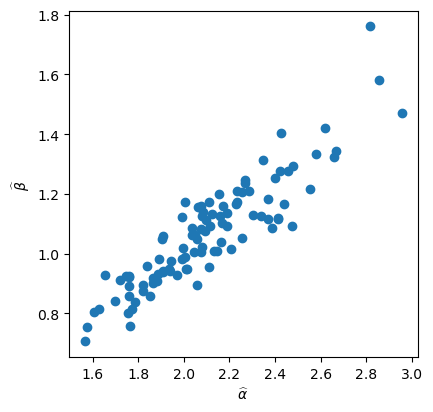

array([[0.08298623, 0.04663318],
       [0.04663318, 0.03211992]])

In [9]:
mles = []

for i in range(100):
    xs = gamma.rvs(2,scale=1,size=100)
    mles.append(gammamle(xs)[0])

mles = np.array(mles)

plt.figure(figsize=[4.5,4.5])
plt.scatter(mles[:,0],mles[:,1])
plt.xlabel("$\widehat \\alpha$")
plt.ylabel("$\widehat \\beta$")

plt.show()

np.cov(mles,rowvar=False)

\newpage

**Comments:** 

1. We are using the curvature in the *observed* log-likelihood function to approximate the variance of $\boldsymbol{\hat \theta}$, i.e., using a fixed data set. In some cases, with simpler probability models, it is possible to derive the *expected* curvature over random data sets. This is referred to as the **Fisher Information Matrix**,
and often denoted ${\bf I}_n(\theta)$.

2. MLEs are not necessarily unbiased estimators of the parameters, but they are **asymptotically unbiased**, meaning that the bias will converge to zero as the sample size increases.

3. It is possible to show that the lower bound on the variance of any unbiased estimator of $\boldsymbol{\theta}$ is ${\bf I}_n(\theta)^{-1}$. This is the **Cram&eacute;r-Rao Lower Bound**. In combination with the previous point, we now have assurance that the MLE has (approximately) the smallest possible MSE. This is a primary reason for preferring the MLE as a method for constructing estimators.


\newpage

## Estimating Functions of Parameters {-}

It is often the case that we are not interested specifically in the value of $\boldsymbol{\theta}$, but instead in estimating ${\bf g}({\boldsymbol \theta})$.

In the example we just considered, the model contains parameters $\boldsymbol{\theta} = (\alpha, \beta)$, but maybe we are actually interested in estimating
\begin{equation*}
g_1(\alpha, \beta) = \frac{\alpha}{\beta}
\end{equation*}
and
\begin{equation*}
g_2(\alpha, \beta) = \frac{\alpha}{\beta^2}
\end{equation*}
since these are the mean and variance of the distribution, respectively.

Another example: We may be interested in estimating probability of extreme **tail events** for the purposes of risk management.

\newpage

Fortunately, MLEs satisfy the following **invariance property**: If $\boldsymbol{\hat\theta}$ is the MLE for $\boldsymbol{\theta}$, then 
${\bf g}(\boldsymbol{\hat\theta})$ is the MLE for ${\bf g}(\boldsymbol{\theta})$.

Another way to view this: If you were to rewrite (reparameterize)
the probability model in terms of ${\bf g}(\boldsymbol{\theta})$ and maximize the
likelihood over these new parameters, you would end up with the same fitted model.

**Exercise:** When $X_1, X_2, \ldots, X_n$ are iid Exponential$(\lambda)$, the MLE for $\lambda$ can be shown to be $1/\overline{X}$. What is the MLE for the $P(X_i > a)$?

\answerlines{9}

**Exercise:** Does unbiasedness satisfy a similar invariance property?

\answerlines{6}

\newpage

**Comment:** The invariance property can be exploited to help with numerical issues of optimization. It tells us that we can maximize the likelihood using parameterization that is easiest to maximize, and then we can transform into the parameters of actual interest.

For example, your model may often include a variance parameter $\sigma^2$ which is, naturally, nonnegative. If the true value of $\sigma^2$ is close to zero, the iterative algorithm may encounter problems when getting close to that boundary. Instead, it is common to use $\tau = \log(\sigma^2)$ as the parameter to maximize over.

\newpage

We can also make a statement regarding the distribution of ${\bf g}(\boldsymbol{\hat \theta})$.

To see this, it is useful to consider the general statement of the **Delta Method** in
the one-dimensional case.

**The Delta Method (one-dimensional):** If $Y_n$ is approximately $N(\mu, \sigma_n^2)$
and $\sigma_n^2 \rightarrow 0$ as $n$ increases,
then $g(Y_n)$ is approximately $N(g(\mu), (g'(\mu))^2 \sigma_n^2)$, assuming that $g'(\mu)$ exists and is not zero.

The Delta Method can be useful in general situations where, for example, one wants to approximate the distribution of $g(\overline{X})$. The CLT gives us conditions under which $\overline{X}$ is approximately $N(\mu, \sigma^2/n)$, so $g(\overline{X})$ is also approximately normal.

**Exercise:** Suppose that $X_1, X_2, \ldots, X_n$ are iid from some distribution with positive support and finite mean and variance. What is the (approximate) distribution of $\log(\overline{X})$?

\answerlines{10}

\newpage

The following picture helps to visualize the Delta Method.

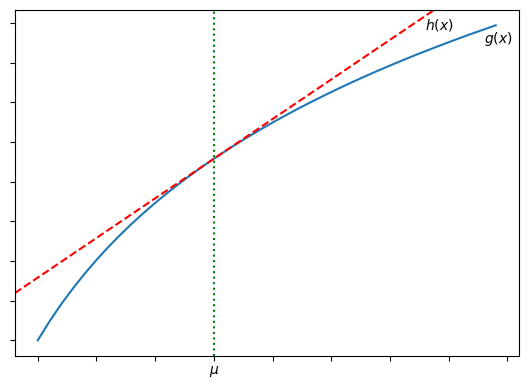

In [10]:
xgrid = np.arange(1,5,0.1)
mu = 2.5

plt.figure(figsize=[6.5,4.5])
plt.plot(xgrid,np.log(xgrid))
plt.axline([mu,np.log(mu)],slope=1/mu,linestyle="--",color="red")
plt.axvline(mu,color="green",linestyle=":")
plt.text(4.8,1.5,"$g(x)$")
plt.text(4.3,1.57,"$h(x)$")
plt.tick_params(labelbottom=False, labelleft=False)
plt.text(mu,-.17,"$\mu$",ha="center")
plt.show()

The line $h(x)$ is tangent to $g(x)$ at $\mu$, so it is of the form
\begin{equation*}
   h(x) = a + g'(\mu) x.
\end{equation*}
If $Y_n$ has (approximately) the $N(\mu, \sigma_n^2)$ distribution, then $h(Y_n)$ is (approximately) $N(g(\mu), (g'(\mu))^2 \sigma_n^2)$.

Then, as $n$ increases, the distribution of $Y_n$ concentrates around $\mu$, so $g(Y_n)$ behaves more and more like $h(Y_n)$.

\newpage

Since we know that, in most situations, the MLE for $\theta$ is approximately normal, the Delta Method gives us conditions under which we can say that $g(\theta)$ is approximately normal.

The general result is as follows:

**The Delta Method (Multiparameter Case):** Suppose that $\boldsymbol{\hat \theta}$
is approximately normally distributed with variance $\boldsymbol{\Sigma}$. The
function ${\bf g}$ returns a $m$-dimensional vector, where $m \leq p$. 

Let ${\bf G}$ denote the **Jacobian matrix** of the function ${\bf g}$, i.e., the $m$ by $p$ matrix whose $(i,j)$ entry is
\begin{equation*}
   \frac{\partial g_i(t_1,t_2,\ldots, t_p)}{\partial t_j}.
\end{equation*}
Then, ${\bf g}(\boldsymbol{\hat \theta})$ is approximately normal with variance
\begin{equation*}
   {\bf G} \boldsymbol{\Sigma} {\bf G}^T,
\end{equation*}
assuming that the resulting matrix is of full rank.

There is a function `Jacobian()` in `numdifftools` that works much like does `Hessian()`.

\newpage

**Exercise:** 
**Value at Risk (VaR)** is a risk management measure that quantifies the maximum expected financial loss a portfolio could suffer over a time period, given a confidence level.

Specifically, VaR at level $\alpha$ is defined as the smallest value $c$ such that
\begin{equation*}
P(L > c) \leq \alpha
\end{equation*}
where $L$ is a random variable which models the distribution of *losses* over the desired time period.

The **Conditional Value at Risk (CVaR)**, also known as **Expected Shortfall (ES)**, takes this a step further by quantifying the expected value of losses that exceed a VaR threshold.

Mathematically, for a given confidence level $\alpha$, CVaR is defined as the conditional expectation of $L$ given that the loss strictly exceeds the VaR at that confidence level:
\begin{equation*}
E(L | L > {\rm VaR}_{\alpha}).
\end{equation*}

Assume that $L$ is normal. Write and test a Python function that takes as inputs a sample of loss values and a value for $\alpha$, and returns the 
MLE for ${\rm CVaR}_{\alpha}$, along with a 95% confidence interval for it.

\answerlines{50}